# 2. Feature engineering

Goal: forecast the **daily statistic of each pollutant on day D+h** (h = 1, 2, 3) from what is known
at the end of day D. The code lives in `src/aaqa/features/build.py`; this notebook documents it.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aaqa import config as paths
from aaqa.aqi import WHO_PM25_24H, WHO_PM25_ANNUAL
from aaqa.pipeline import load_daily, load_hourly
from aaqa.pollutants import POLLUTANTS

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.rcParams["figure.figsize"] = (11, 4)
pd.set_option("display.precision", 2)
from aaqa.features.build import TARGET, build_features, make_supervised

In [2]:
daily = load_daily()
features = build_features(daily)
print(features.shape)
pd.DataFrame({key: [spec.target, spec.statistic] for key, spec in POLLUTANTS.items()}, index=["target column", "statistic"]).T

(1540, 59)


,target column,statistic
pm2_5,pm2_5_mean,24-h mean
pm10,pm10_mean,24-h mean
ozone,ozone_max8h,max 8-h mean
nitrogen_dioxide,nitrogen_dioxide_max,max hourly
sulphur_dioxide,sulphur_dioxide_max,max hourly
carbon_monoxide,carbon_monoxide_max8h,max 8-h mean


## Feature families
| Family | Examples | Role |
|---|---|---|
| Current level | `pm2_5_mean`, `pm10_mean`, `ozone_max8h`… | pollution is very persistent |
| PM2.5 history | `pm2_5_lag1..7`, `pm2_5_roll3..30`, `pm2_5_std7` | recent trend and variability |
| Other pollutants' history | `pm10_lag1`, `ozone_roll3`, `carbon_monoxide_roll7`… | same, reduced set |
| Dust | `dust_mean`, `dust_lag1`, `dust_roll3` | harmattan episodes |
| Weather | humidity, rain (`rain_roll3`, `dry_days`), wind (u/v components), temperature range | dispersion and wash-out |
| Calendar | `doy_sin/cos`, `is_harmattan`, `is_dry_season`, `target_dow` | seasonality; the target day is known in advance |

Wind is averaged **as a vector**: the mean of 350° and 10° is 0° (north), not 180°.

## Persistence: today's pollution predicts tomorrow's

In [3]:
pd.DataFrame({spec.name: {f"lag {k}": daily[spec.target].autocorr(k) for k in (1, 2, 3, 7, 14, 30)}
              for spec in POLLUTANTS.values()}).T

,lag 1,lag 2,lag 3,lag 7,lag 14,lag 30
PM2.5,0.94,0.85,0.77,0.57,0.35,0.24
PM10,0.93,0.83,0.74,0.54,0.32,0.22
O3,0.88,0.78,0.73,0.65,0.53,0.39
NO2,0.76,0.56,0.47,0.48,0.48,0.39
SO2,0.83,0.73,0.68,0.62,0.62,0.58
CO,0.86,0.76,0.71,0.70,0.66,0.58


## Link between each feature and the D+1 PM2.5 target

In [4]:
X, y = make_supervised(features, 1)
X.corrwith(y, method="spearman").drop(TARGET).sort_values(key=abs, ascending=False).head(15).to_frame("Spearman with D+1")

,Spearman with D+1
pm2_5_max,0.88
pm2_5_roll3,0.86
pm2_5_roll7,0.84
pm10_mean,0.84
pm2_5_lag1,0.81
pm2_5_roll14,0.81
pm10_roll3,0.80
pm10_roll7,0.78
pm2_5_lag2,0.77
pm2_5_roll30,0.77


## Leakage check
If the data is changed **after** a date, no feature **before** that date may change. This is automated in
`tests/test_features.py::test_no_future_leakage`.

In [5]:
altered = daily.copy(); altered.iloc[500:] *= 10
assert build_features(altered).iloc[:500].equals(features.iloc[:500])
print("OK: no information from the future is used")

OK: no information from the future is used


## Why a log-ratio target?
The mean level fell sharply from 2023 to 2025. Decision trees cannot extrapolate outside the levels seen
in training, so they predict **log(1+C on D+h) − log(1+C on D)**, i.e. the relative change, which is then
converted back to µg/m³.

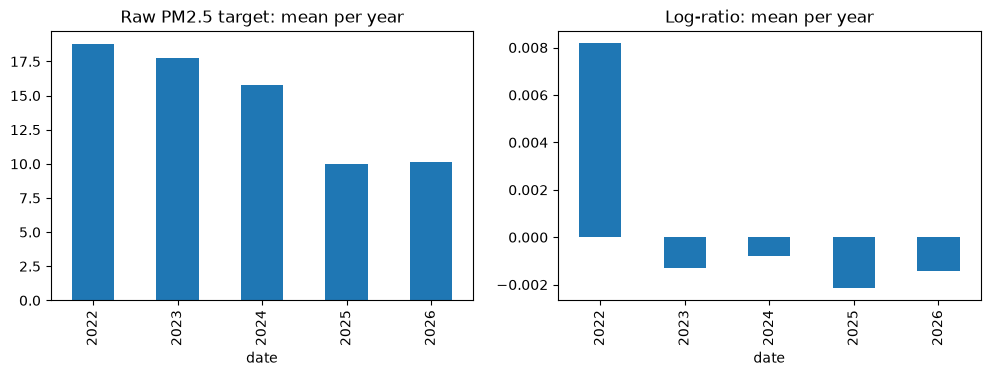

In [6]:
ratio = np.log1p(y) - np.log1p(X[TARGET])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
y.groupby(y.index.year).mean().plot.bar(ax=axes[0], title="Raw PM2.5 target: mean per year")
ratio.groupby(ratio.index.year).mean().plot.bar(ax=axes[1], title="Log-ratio: mean per year")
plt.show()